In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os, sys
ROOT = '/content/drive/MyDrive/DSP_Deconv'
for d in ['lib', 'data/raw', 'data/processed', 'results', 'figures', 'configs']:
    os.makedirs(f'{ROOT}/{d}', exist_ok=True)
if f'{ROOT}/lib' not in sys.path:
    sys.path.insert(0, f'{ROOT}/lib')
print(os.listdir(ROOT))

['lib', 'data', 'results', 'figures', 'configs', '04_real_data.ipynb', '00_setup_data.ipynb', '05_figures_new.ipynb', '01_forward_baselines_new.ipynb', '03_experiments_new.ipynb', '02_proposed_new.ipynb', '04_real_data_new.ipynb']


In [ ]:
!pip -q install scikit-image tifffile pyyaml

import sys
import importlib
if 'imp' not in sys.modules:
    from types import ModuleType
    imp_mock = ModuleType('imp')
    imp_mock.reload = importlib.reload
    sys.modules['imp'] = imp_mock

%load_ext autoreload
%autoreload 2
import numpy as np, scipy, skimage, matplotlib.pyplot as plt
print('numpy', np.__version__, '| scipy', scipy.__version__, '| skimage', skimage.__version__)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
numpy 2.1.3 | scipy 1.16.3 | skimage 0.25.2


In [ ]:
import yaml
cfg = yaml.safe_load(open(f'{ROOT}/configs/params.yaml'))
cfg

{'crop': 256,
 'eps_band': 0.001,
 'gauss_noise': [0.005, 0.01, 0.02, 0.05],
 'poisson_peaks': [30, 100, 300],
 'psf_sigmas': [1.5, 2.5, 4.0],
 'seeds': [0, 1, 2, 3, 4]}

In [ ]:
import platform, numpy, scipy, skimage, yaml
from pathlib import Path

with open(f'{ROOT}/results/versions.txt', 'w') as f:
    f.write(f'python {platform.python_version()}\nnumpy {numpy.__version__}\nscipy {scipy.__version__}\nskimage {skimage.__version__}\n')

oct_files = sorted(p for p in Path(f'{ROOT}/data/raw/OCT').glob('*.jpeg') if not p.name.startswith('._'))

split = dict(
    dev=dict(subset='WideField_BPAE_B', fovs=list(range(1, 19)), used_for_tuning=[1, 2, 3]),
    test_synthetic=dict(subsets=['Confocal_BPAE_B', 'TwoPhoton_MICE'], fov=19, crops='4 quadrants of 256x256'),
    test_real_fmd=dict(subsets=['Confocal_BPAE_B', 'TwoPhoton_MICE'], fov=19, raw_frame=0, reference='avg50'),
    real_oct=[p.name for p in oct_files],
)
yaml.safe_dump(split, open(f'{ROOT}/configs/split.yaml', 'w'), sort_keys=False)
print(open(f'{ROOT}/results/versions.txt').read())
print(len(oct_files), 'OCT images')

python 3.13.18
numpy 2.1.3
scipy 1.16.3
skimage 0.25.2

13 OCT images


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from forward import *; from data import *; from baselines import *; from proposed import *; from metrics import *
from baselines import _apply                   
tuned = yaml.safe_load(open(f'{ROOT}/configs/tuned.yaml'))

PAD = 32                                        
pad = lambda im: np.pad(im, PAD, mode='reflect')
unpad = lambda im: im[PAD:-PAD, PAD:-PAD]
LINEAR = ['wiener_const', 'tikhonov_gcv', 'proposed']

def design(method, y, psf):
    """lambda(w) chosen from the NOISY image only; RL has no lambda (returns None)."""
    yp = pad(y)
    if method == 'wiener_const':
        return np.full(yp.shape, tuned['nsr'])
    if method == 'tikhonov_gcv':
        return gcv_lambda(yp, psf)[0] * np.abs(laplacian_otf(yp.shape)) ** 2
    if method == 'proposed':
        return adaptive_wiener(yp, psf, return_info=True)[1]['lam']
    return None

def restore(im, psf, lam):
    """Apply the same filter to any image (noisy frame or clean reference)."""
    if lam is None:
        return unpad(rl(pad(im), psf, tuned['rl_iter']))
    return unpad(_apply(pad(im), psf2otf(psf, pad(im).shape), lam))

def mtf50(T):
    """Frequency (cycles/px) where a radially averaged transfer function T(w) first drops below 0.5."""
    w = freq_grid(T.shape); edges = np.linspace(0, 0.5, 101)
    for a, b in zip(edges[:-1], edges[1:]):
        if np.median(T[(w >= a) & (w < b)]) < 0.5:
            return (a + b) / 2
    return 0.5

def chain_mtf50(psf, lam, shape):
    """Resolution delivered by blur + restoration: G(w)H(w) = |H|^2 / (|H|^2 + lambda)."""
    H2 = np.abs(psf2otf(psf, shape)) ** 2
    return mtf50(H2 / (H2 + lam))

In [ ]:
rows, panels = [], {}
for subset in ['Confocal_BPAE_B', 'TwoPhoton_MICE']:
    gt, raw = fmd_pair(subset, 19, frame=0)
    gt, raw = norm_pair(gt, raw)
    gt, raw = center_crop(gt, cfg['crop']), center_crop(raw, cfg['crop'])
    for s in [1.0, 1.5, 2.0]:                    
        psf = gaussian_psf(psf_size(s), s)
        shape = pad(raw).shape
        rows.append(dict(subset=subset, psf=s, method='observed', noise_gain=1.0,
                         mtf50=mtf50(np.abs(psf2otf(psf, shape)))))
        for m in LINEAR + ['rl']:
            lam = design(m, raw, psf)
            xr, xg = restore(raw, psf, lam), restore(gt, psf, lam)
            rows.append(dict(subset=subset, psf=s, method=m,
                             noise_gain=noise_gain(xr, xg, raw, gt),
                             mtf50=chain_mtf50(psf, lam, shape) if lam is not None else np.nan))
            if s == 1.5:
                panels[(subset, m)] = xr
        panels[(subset, 'raw')], panels[(subset, 'avg50')] = raw, gt

fmd = pd.DataFrame(rows)
fmd.to_csv(f'{ROOT}/results/real_fmd.csv', index=False)
fmd.pivot_table(index=['subset', 'psf'], columns='method', values=['noise_gain', 'mtf50']).round(3)

mtf50                                    noise_gain  \
method              observed proposed tikhonov_gcv wiener_const   observed   
subset          psf                                                          
Confocal_BPAE_B 1.0    0.188    0.208        0.218        0.298        1.0   
                1.5    0.128    0.188        0.208        0.198        1.0   
                2.0    0.098    0.173        0.212        0.152        1.0   
TwoPhoton_MICE  1.0    0.188    0.202        0.198        0.298        1.0   
                1.5    0.128    0.178        0.188        0.198        1.0   
                2.0    0.098    0.162        0.182        0.152        1.0   

                                                               
method              proposed     rl tikhonov_gcv wiener_const  
subset          psf                                            
Confocal_BPAE_B 1.0    0.681  0.478        0.726        1.510  
                1.5    0.938  0.416        1.235        1.135  
                2.0    1.469  0.382        4.290        0.955  
TwoPhoton_MICE  1.0    0.603  0.373        0.582        1.557  
                1.5    0.756  0.308        0.866        1.115  
                2.0    1.110  0.274        1.701        0.904

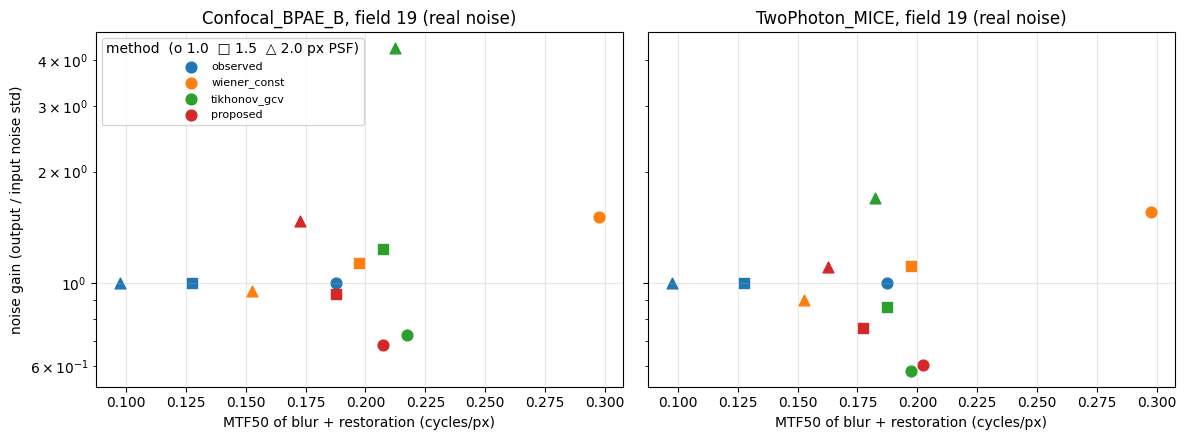

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
marker = {1.0: 'o', 1.5: 's', 2.0: '^'}
for ax, subset in zip(axes, ['Confocal_BPAE_B', 'TwoPhoton_MICE']):
    d = fmd[(fmd.subset == subset) & fmd.method.isin(['observed'] + LINEAR)]
    for i, m in enumerate(['observed'] + LINEAR):
        for s in [1.0, 1.5, 2.0]:
            r = d[(d.method == m) & (d.psf == s)]
            ax.scatter(r.mtf50, r.noise_gain, color=f'C{i}', marker=marker[s], s=60,
                       label=m if s == 1.0 else None)
    ax.set_title(f'{subset}, field 19 (real noise)'); ax.set_xlabel('MTF50 of blur + restoration (cycles/px)')
    ax.set_yscale('log'); ax.grid(alpha=0.3)
axes[0].set_ylabel('noise gain (output / input noise std)')
axes[0].legend(title='method  (o 1.0  □ 1.5  △ 2.0 px PSF)', fontsize=8)
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/real_fmd_tradeoff.png', dpi=300); plt.show()

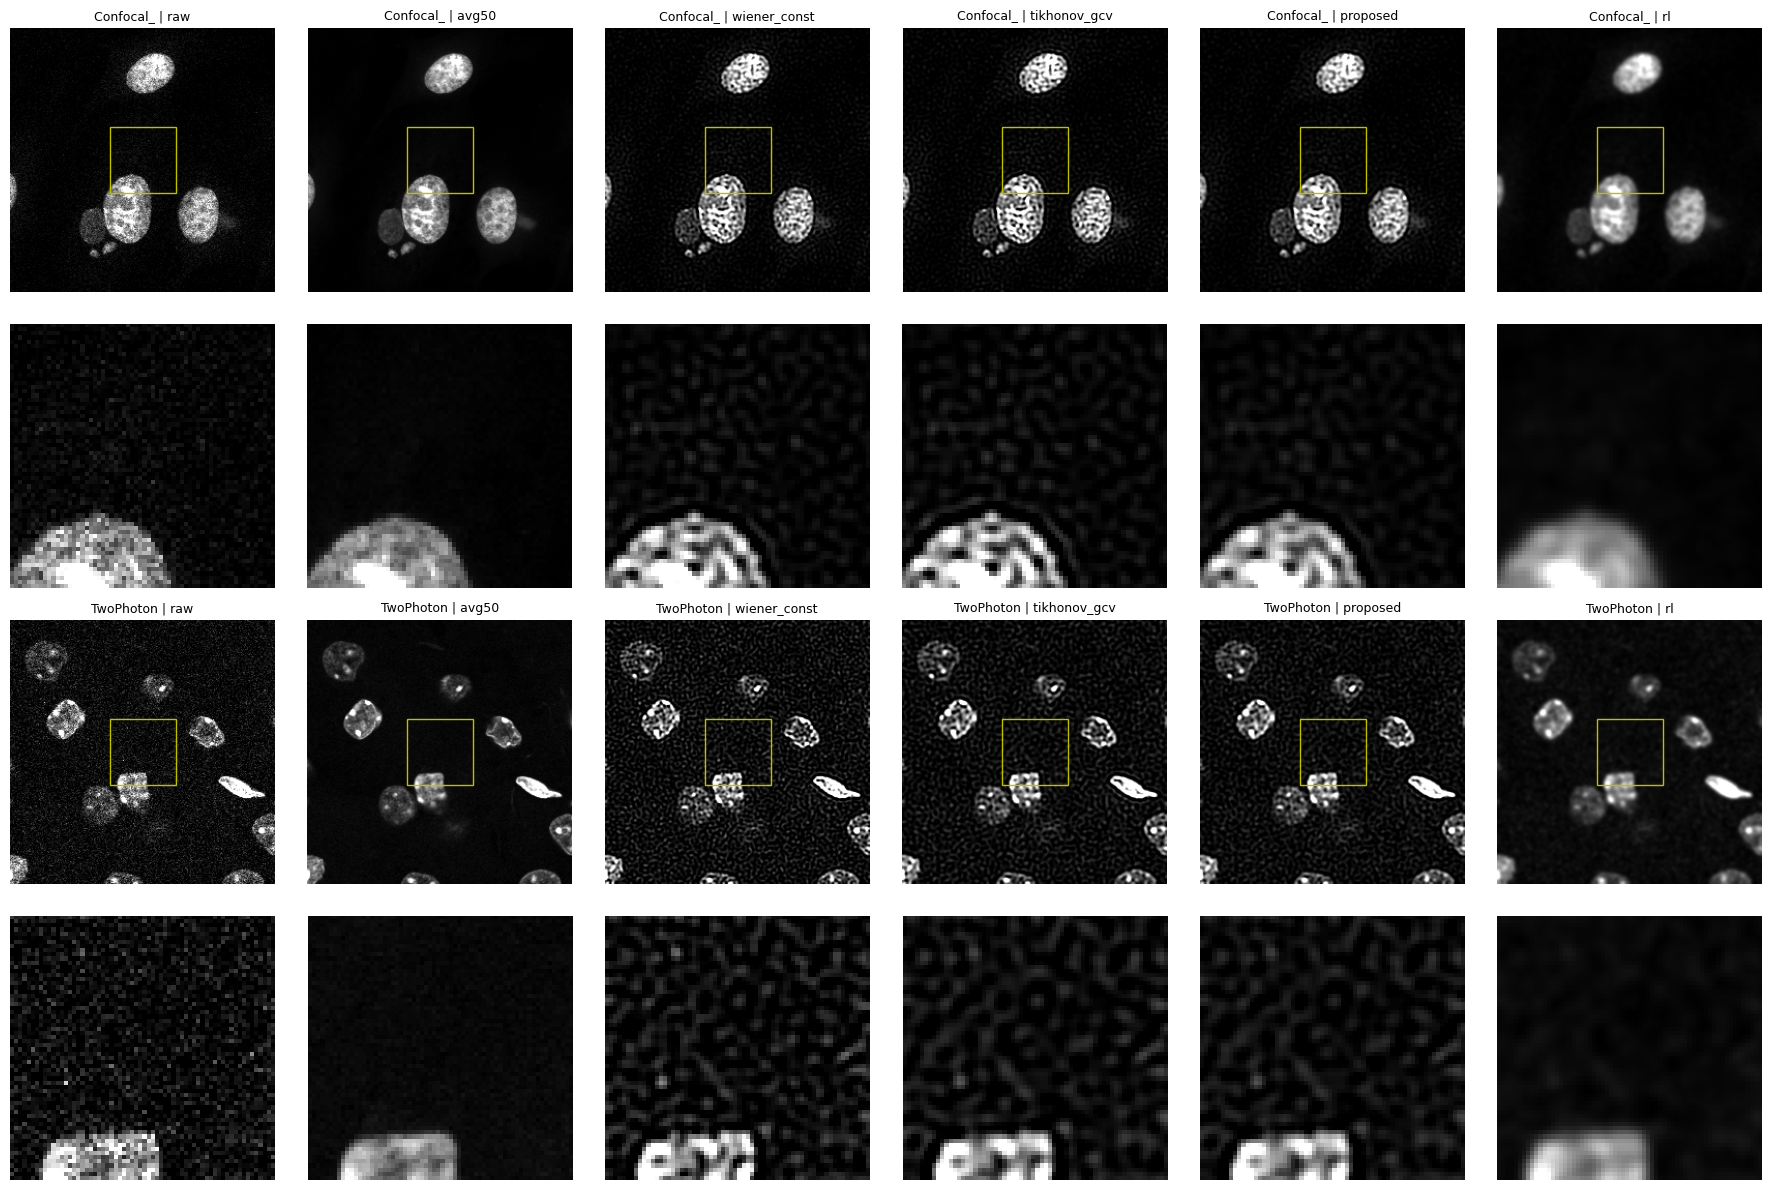

In [ ]:
order = ['raw', 'avg50'] + LINEAR + ['rl']
zr, zc, zs = 96, 96, 64
fig, ax = plt.subplots(4, len(order), figsize=(3 * len(order), 12))
for row, subset in enumerate(['Confocal_BPAE_B', 'TwoPhoton_MICE']):
    for col, k in enumerate(order):
        im = np.clip(panels[(subset, k)], 0, 1)
        ax[2 * row, col].imshow(im, cmap='gray'); ax[2 * row, col].set_title(f'{subset[:9]} | {k}', fontsize=9)
        ax[2 * row, col].add_patch(plt.Rectangle((zc, zr), zs, zs, fill=False, ec='y'))
        ax[2 * row + 1, col].imshow(im[zr:zr + zs, zc:zc + zs], cmap='gray')
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/real_fmd_panels.png', dpi=200); plt.show()

In [ ]:
def background_band(z, h=24):
    """Darkest h-row band in the top 40% of the B-scan (vitreous, above the retina): noise-only region."""
    top = z[: int(0.4 * z.shape[0])]
    r = int(np.argmin([top[i:i + h].mean() for i in range(top.shape[0] - h)]))
    return slice(r, r + h)

k = psf_size(2.0); g = gaussian_psf(k, 2.0)[k // 2:k // 2 + 1, :]; g /= g.sum()    
oct_rows, oct_panels = [], {}
for p in oct_files:
    im = skimage.io.imread(p).astype(float)
    im = im.mean(-1) if im.ndim == 3 else im
    z = np.log1p(im) / np.log1p(255)                                              
    band = background_band(z)
    for m in LINEAR:
        lam = design(m, z, g)
        zh = restore(z, g, lam)
        oct_rows.append(dict(image=p.name, method=m,
                             background_noise_ratio=zh[band].std() / z[band].std(),
                             lateral_mtf50=chain_mtf50(g, lam, pad(z).shape)))
        if p == oct_files[0]:
            oct_panels[m] = zh
    if p == oct_files[0]:
        oct_panels['observed'], oct_band = z, band
oct_df = pd.DataFrame(oct_rows)
oct_df.to_csv(f'{ROOT}/results/real_oct.csv', index=False)
oct_df.groupby('method')[['background_noise_ratio', 'lateral_mtf50']].agg(['mean', 'std']).round(3)

background_noise_ratio        lateral_mtf50       
                               mean    std          mean    std
method                                                         
proposed                      1.020  0.205         0.179  0.014
tikhonov_gcv                  3.897  6.957         0.204  0.064
wiener_const                  1.453  0.079         0.212  0.000

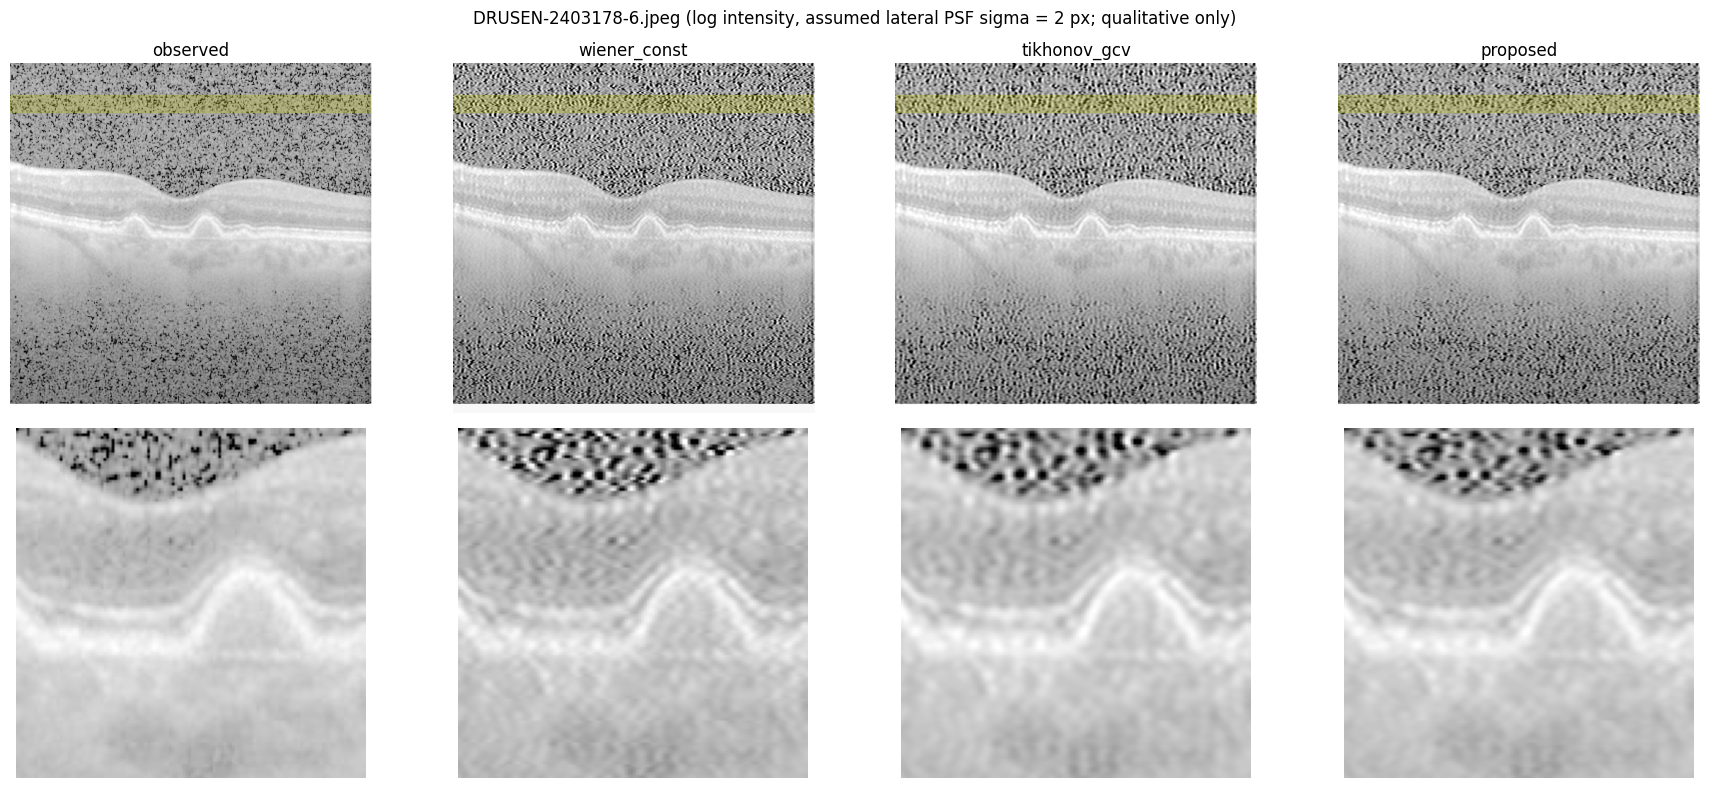

In [ ]:
order = ['observed'] + LINEAR
fig, ax = plt.subplots(2, len(order), figsize=(4.5 * len(order), 8))
for col, k in enumerate(order):
    im = np.clip(oct_panels[k], 0, 1)
    ax[0, col].imshow(im, cmap='gray'); ax[0, col].set_title(k)
    ax[0, col].axhspan(oct_band.start, oct_band.stop, color='y', alpha=0.25)
    h, w = im.shape
    ax[1, col].imshow(im[h // 3:h // 3 + 128, w // 2 - 64:w // 2 + 64], cmap='gray')
for a in ax.ravel(): a.axis('off')
plt.suptitle(f'{oct_files[0].name} (log intensity, assumed lateral PSF sigma = 2 px; qualitative only)')
plt.tight_layout(); plt.savefig(f'{ROOT}/figures/real_oct_panels.png', dpi=200); plt.show()